[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

获取凭据、选择后端、构建线路、提交任务并查询结果。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。量子云步骤默认关闭；只有需要访问云端时才将 `RUN_ON_QCLOUD` 改为 `True`，并在启动 Jupyter 前准备好 `APIKEY` 环境变量。

In [1]:
RUN_ON_QCLOUD = False

if RUN_ON_QCLOUD:
    import os
    if not os.environ.get("APIKEY"):
        raise ValueError("请先设置 APIKEY 环境变量，再开启量子云步骤。")


# 使用量子计算机运行

**流程**：
1. 获取APIKEY
2. 选择可用后端
3. 构造量子线路
4. 提交量子线路，得到计算任务实例
5. 根据任务实例对象获取任务计算结果

In [2]:
import os
from pyqpanda3.core import H, CNOT, measure, QProg, draw_qprog
from pyqpanda3.qcloud import QCloudOptions, QCloudService, QCloudJob

## 第一步：获取 API Key 并配置环境变量

登录[本源量子控制台 API Key 页面](https://console.originqc.com.cn/zh/apikey)，按页面提示创建并复制密钥。将下面命令中的 `替换为实际的APIKey` 替换为自己的密钥，在**仓库根目录的终端**执行，不要将真实密钥写入 Notebook。

**Windows PowerShell：**

```powershell
$env:APIKEY = "替换为实际的APIKey"
uv run --locked jupyter lab
```

**macOS / Linux（Bash/Zsh）：**

```bash
export APIKEY="替换为实际的APIKey"
uv run --locked jupyter lab
```

环境变量仅对当前终端及其启动的进程生效。如果 Jupyter 已在运行，请先保存 Notebook，停止 Jupyter 服务及内核，再从设置了 `APIKEY` 的终端重新启动；仅刷新网页或重启原服务中的内核不能继承另一终端的新变量。

本例通过 `os.getenv('APIKEY')` 读取密钥。确认需要访问云端并提交任务时，再将开头的 `RUN_ON_QCLOUD` 改为 `True`，从头执行 Notebook。

In [3]:
if RUN_ON_QCLOUD:
    APIKEY = os.getenv('APIKEY')
    service = QCloudService(APIKEY)
else:
    print("量子云步骤未启用：未连接远端、未提交任务。")


量子云步骤未启用：未连接远端、未提交任务。


**注**：选择可用后端之前，先查看当前有哪些后端，为True表示可用，也可以在云平台中看到

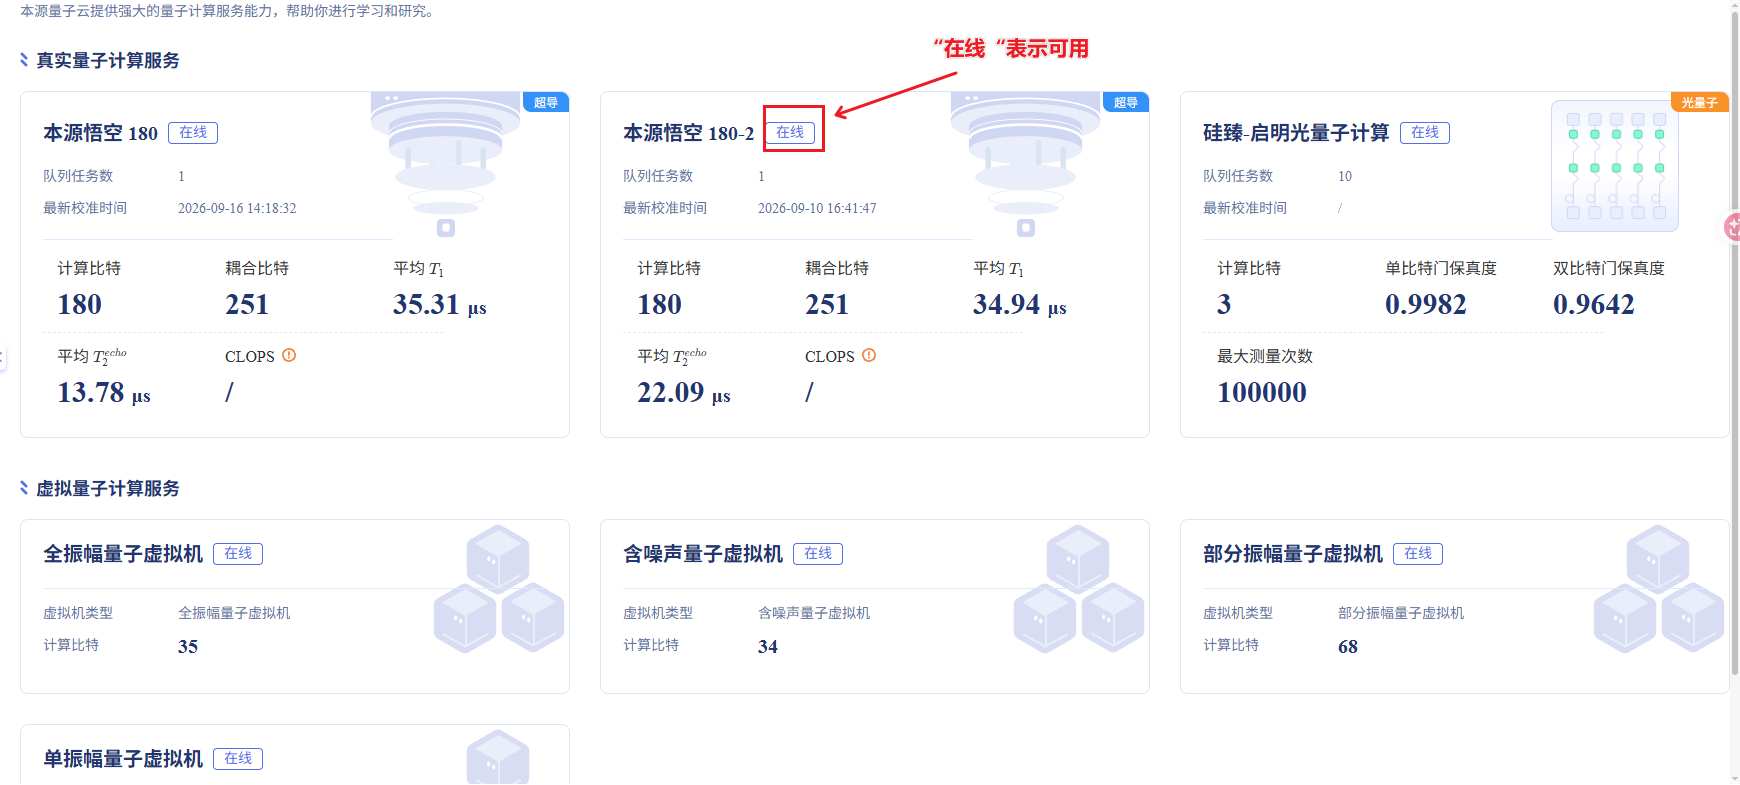

## 第二步：选择可用后端

In [4]:
if RUN_ON_QCLOUD:
    # 查看可用计算后端
    backends = service.backends()
    print(backends)
else:
    print("量子云步骤未启用：未连接远端、未提交任务。")


量子云步骤未启用：未连接远端、未提交任务。


In [5]:
if RUN_ON_QCLOUD:
    # WK_C180是真机，选择使用这个后端
    backend = service.backend('WK_C180')
else:
    print("量子云步骤未启用：未连接远端、未提交任务。")


量子云步骤未启用：未连接远端、未提交任务。


## 第三步：构造量子线路

In [6]:
bell_state_prog = QProg(2)
bell_state_prog << H(0) << CNOT(0, 1) << measure(0, 0) << measure(1, 1)
print(draw_qprog(bell_state_prog))


          ┌─┐         ┌─┐     
q_0:  |0>─┤H├ ───*── ─┤M├──── 
          └─┘ ┌──┴─┐  └╥┘ ┌─┐ 
q_1:  |0>──── ┤CNOT├ ──╫──┤M├ 
              └────┘   ║  └╥┘ 
 c :   / ══════════════╩═══╩═
                        0   1




## 第四步：提交量子线路

In [7]:
if RUN_ON_QCLOUD:
    job = backend.run(bell_state_prog, 1000)
    print('当前任务的ID为：', job.job_id())
else:
    print("量子云步骤未启用：未连接远端、未提交任务。")


量子云步骤未启用：未连接远端、未提交任务。


## 第五步：获取计算结果

In [8]:
if RUN_ON_QCLOUD:
    # 查询任务结果，计算时间与任务队列中任务数量有关
    result = job.result().get_probs()
    print(result)
else:
    print("量子云步骤未启用：未连接远端、未提交任务。")


量子云步骤未启用：未连接远端、未提交任务。


## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

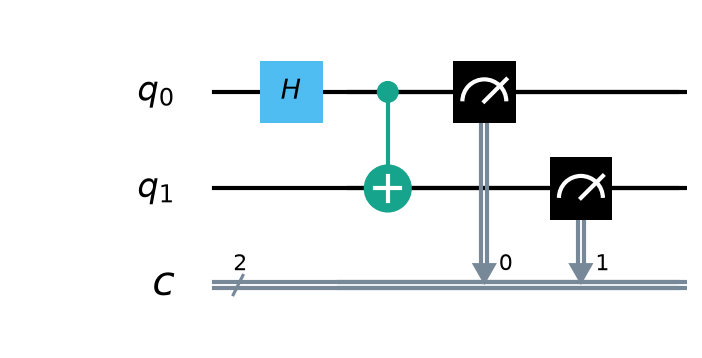

In [9]:
from pathlib import Path
from IPython.display import Image, display
import pyqpanda3.visualization

repo_root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
figure_dir = repo_root / ".tmp/notebook-figures/day1"
figure_dir.mkdir(parents=True, exist_ok=True)
image_path = figure_dir / "03_quantum_cloud.png"
bell_state_prog.draw("pic", filename=str(image_path), with_gate_params=True)
display(Image(filename=str(image_path)))
